# PathSnap - comparison of the 7 candidate-scoring models

**Task.** Every GPS point has up to 12 candidate road segments within 50 m. Each model looks at one
(GPS point, candidate road) pair, described by 22 features, and predicts the probability that this is
the correct road. The highest-scoring candidate is the model's answer for that point.

**Protocol (same for every model).**
1. 5-fold **GroupKFold** cross-validation on the **80 training trips**. Folds are split by trip, so no trip is in both training and validation.
2. Refit on all 80 trips and test once on the **10 student-test trips** (19,160 GPS points).

**Metrics.** **Top-1 accuracy** (main metric: is the chosen road correct?), Macro F1, precision, recall, log loss, route continuity.

This notebook loads each trained model and scores the student-test trips **live**, building the features from the raw
`.track/.nodes/.arcs` files. The CV fold scores were recorded during training (`results/models/cv_fold_results.csv`).

In [1]:
import sys, time, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
from IPython.display import display, Image
from pathsnap.config import FEATURES, MODELS, RESULTS
from pathsnap.data_io import list_trips, load_trip
from pathsnap.features import prepare_trip, build_candidates
from pathsnap.labels import align_route
from pathsnap.hmm import classifier_only, viterbi_decode
from pathsnap.metrics import pair_metrics, route_continuity, confusion
from pathsnap.pipeline import PathSnapPredictor
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.dpi"] = 100

## Step 1 - build the student-test features live from the raw files

In [2]:
t0 = time.time()
trips, rows = {}, []
for tid in list_trips("student_test"):
    trip = load_trip(tid, "student_test")
    proj, net, xy = prepare_trip(trip)
    c = build_candidates(trip, net, xy).sort_values(["obs", "dist"]).reset_index(drop=True)
    ref, _, _ = align_route(xy, net, trip.route)            # reference labels - used only for scoring
    c["label"] = (c["arc"].to_numpy() == ref[c["obs"].to_numpy()]).astype(int)
    c.insert(0, "trip_id", tid)
    trips[tid] = (trip, net, xy, ref)
    rows.append(c)
df = pd.concat(rows, ignore_index=True)
X, y = df[FEATURES].to_numpy(np.float32), df["label"].to_numpy()
print(f"{len(trips)} trips, {sum(len(v[2]) for v in trips.values()):,} GPS points, {len(df):,} candidate rows x {len(FEATURES)} features ({time.time()-t0:.1f} s)")
print("Features:", ", ".join(FEATURES))

10 trips, 19,160 GPS points, 147,062 candidate rows x 22 features (8.8 s)
Features: dist, dist_rank, dist_minus_min, dist_ratio, n_cands, dist_share, ctx_dist_mean, ctx_dist_max, ctx_minus_min, ctx_rank, heading_diff, cos_heading, heading_rank, heading_valid, speed, dt_prev, dt_next, arc_len, proj_frac, end_dist, out_deg, in_deg


In [3]:
cv = pd.read_csv(RESULTS / "models" / "cv_fold_results.csv")
summary = pd.read_csv(RESULTS / "models" / "model_comparison.csv").set_index("model")
live = []

def top1_and_continuity(p):
    ok = n = 0; cont = []
    for tid, g in df.assign(p=p).groupby("trip_id", sort=False):
        trip, net, xy, ref = trips[tid]
        pred = classifier_only(g, g["p"].to_numpy(), len(xy))
        ok += int((pred == ref).sum()); n += len(xy)
        cont.append((route_continuity(pred, net.arcs), len(xy) - 1))
    return ok / n, sum(a * b for a, b in cont) / sum(b for _, b in cont)

def show_model(name):
    model = joblib.load(MODELS / "experiments" / f"{name}.joblib")
    print("Configuration:", summary.loc[name, "config"])
    print(f"Training rows: {int(summary.loc[name, 'train_rows']):,}   training time: {summary.loc[name, 'fit_time_s']:.1f} s")
    f = cv[cv.model == name][["fold", "f1_macro", "top1_acc", "log_loss", "train_f1_macro"]].rename(columns={
        "f1_macro": "CV Macro F1", "top1_acc": "CV Top-1", "log_loss": "CV log loss", "train_f1_macro": "Train Macro F1"})
    print("\nCross-validation (5 folds, 80 training trips) - recorded during training:")
    display(pd.concat([f, f.drop(columns="fold").agg(["mean", "std"]).reset_index().rename(columns={"index": "fold"})]).set_index("fold"))
    t0 = time.time(); p = model.predict_proba(X)[:, 1]; dt = time.time() - t0
    m = pair_metrics(y, p); acc, cont = top1_and_continuity(p)
    row = {"Model": name, "Top-1 accuracy": acc, "Macro F1": m["f1_macro"], "Precision": m["precision_macro"],
           "Recall": m["recall_macro"], "Log loss": m["log_loss"], "Route continuity": cont, "Predict time (s)": dt}
    live.append(row)
    print("Student-test (10 trips) - computed live now:")
    display(pd.DataFrame([row]).set_index("Model"))
    cm = confusion(y, p); cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(3.6, 3.0))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cmn[i, j]:.1%})", ha="center", va="center", color="white" if cmn[i, j] > .5 else "black", fontsize=9)
    ax.set_xticks([0, 1], ["pred wrong", "pred correct"]); ax.set_yticks([0, 1], ["true wrong", "true correct"])
    ax.set_title(f"{name} - confusion matrix", fontsize=10); plt.tight_layout(); plt.show()

## Model 1 - Logistic Regression
**Family:** Linear / probabilistic  
Learns one weight per feature (log-odds). Fast and gives calibrated probabilities, but cannot model feature interactions.

Configuration: StandardScaler + L2 logistic regression, C=1.0, lbfgs, max_iter=500
Training rows: 1,323,512   training time: 8.7 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.8972,0.8270,0.1450,0.9103
1,0.9225,0.8852,0.1138,0.8987
2,0.8925,0.8168,0.1271,0.9109
3,0.9199,0.8564,0.0984,0.9047
4,0.8884,0.8264,0.1256,0.9108
mean,0.9041,0.8424,0.1220,0.9071
std,0.0159,0.0282,0.0173,0.0054


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
LogisticRegression,0.8537,0.9059,0.9063,0.9054,0.1076,0.9413,0.1561


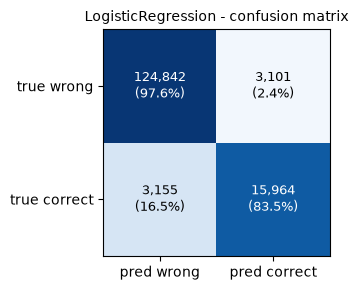

In [4]:
show_model("LogisticRegression")

## Model 2 - Gaussian Naive Bayes
**Family:** Probabilistic  
Assumes every feature is independent given the class. Our distance features are strongly correlated, so it double-counts evidence and is over-confident.

Configuration: QuantileTransformer(normal) + Gaussian Naive Bayes, var_smoothing=1e-9
Training rows: 1,323,512   training time: 6.7 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.8150,0.6768,1.1947,0.8141
1,0.7953,0.5687,1.5716,0.8168
2,0.8285,0.7159,0.8995,0.8130
3,0.8199,0.7140,0.9589,0.8125
4,0.8199,0.6923,1.0054,0.8137
mean,0.8157,0.6735,1.1260,0.8140
std,0.0124,0.0608,0.2725,0.0017


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
GaussianNB,0.6864,0.8138,0.7702,0.9071,1.0412,0.8910,1.9275


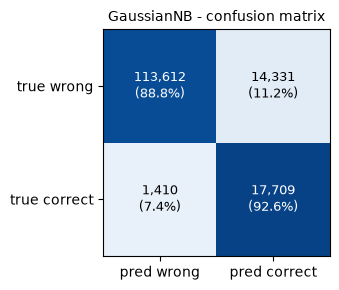

In [5]:
show_model("GaussianNB")

## Model 3 - K-Nearest Neighbours (k = 31, distance-weighted)
**Family:** Instance-based  
Labels a candidate by the 31 most similar training candidates. No training, but prediction is slow (it searches the stored rows).

Configuration: StandardScaler + distance-weighted KNN, k=31, 80k training rows
Training rows: 80,779   training time: 0.0 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.9045,0.8328,0.1773,1.0000
1,0.9348,0.9043,0.1223,1.0000
2,0.8974,0.8143,0.1497,1.0000
3,0.9239,0.8546,0.1088,1.0000
4,0.8933,0.8236,0.1560,1.0000
mean,0.9108,0.8459,0.1428,1.0000
std,0.0178,0.0359,0.0273,0.0000


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
KNN,0.8660,0.9167,0.9257,0.9083,0.1153,0.9391,50.5339


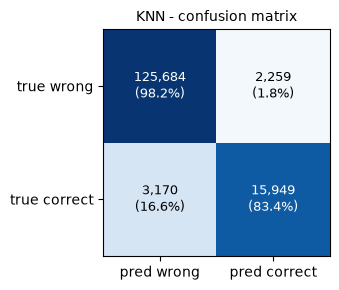

In [6]:
show_model("KNN")

## Model 4 - Decision Tree (depth 12)
**Family:** Tree-based  
Learns if-then rules such as 'closest candidate AND heading matches'. Interpretable, but a single tree has high variance.

Configuration: CART, gini, max_depth=12, min_samples_leaf=50
Training rows: 1,323,512   training time: 42.8 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.9144,0.8425,0.1238,0.9426
1,0.9450,0.9089,0.0802,0.9331
2,0.9154,0.8360,0.1117,0.9407
3,0.9375,0.8708,0.0769,0.9366
4,0.9047,0.8369,0.1088,0.9450
mean,0.9234,0.8590,0.1003,0.9396
std,0.0170,0.0313,0.0206,0.0047


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
DecisionTree,0.8891,0.9338,0.9414,0.9266,0.0783,0.9495,0.0297


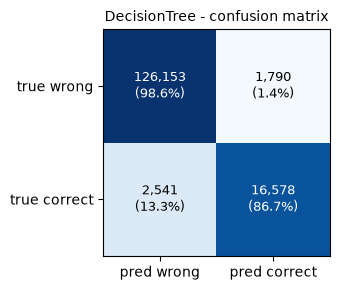

In [7]:
show_model("DecisionTree")

## Model 5 - Random Forest (100 trees)
**Family:** Ensemble - bagging  
Averages 100 trees built on random samples, which reduces the variance of a single tree. Robust, but the model is large (10 MB).

Configuration: 100 trees, max_depth=16, min_samples_leaf=20, max_samples=0.3, sqrt features
Training rows: 1,323,512   training time: 35.8 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.9185,0.8478,0.0997,0.9443
1,0.9485,0.9157,0.0659,0.9363
2,0.9203,0.8419,0.0900,0.9441
3,0.9409,0.8769,0.0639,0.9394
4,0.9093,0.8431,0.0934,0.9467
mean,0.9275,0.8651,0.0826,0.9422
std,0.0165,0.0317,0.0165,0.0042


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
RandomForest,0.8828,0.9340,0.9405,0.9278,0.0717,0.9541,0.3361


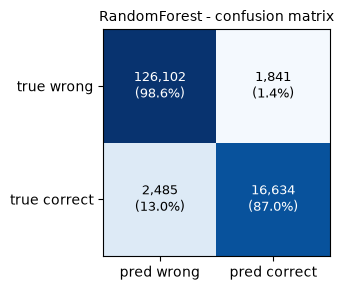

In [8]:
show_model("RandomForest")

## Model 6 - LightGBM (gradient boosting)
**Family:** Ensemble - boosting  
Builds trees one after another, each fixing the errors of the previous ones, and directly minimises log loss. SELECTED model.

Configuration: LightGBM defaults: 100 trees, 31 leaves, lr=0.1
Training rows: 1,323,512   training time: 3.8 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.9178,0.8478,0.1056,0.9455
1,0.9476,0.9134,0.0690,0.9397
2,0.9220,0.8430,0.0920,0.9470
3,0.9383,0.8775,0.0667,0.9434
4,0.9086,0.8422,0.0985,0.9501
mean,0.9269,0.8648,0.0864,0.9451
std,0.0158,0.0308,0.0176,0.0039


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
LightGBM,0.8941,0.9361,0.9380,0.9343,0.0727,0.9510,1.1519


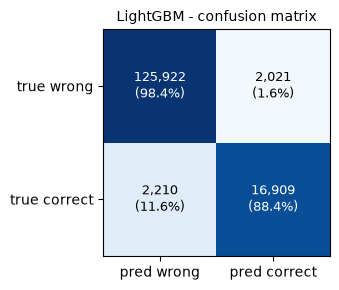

In [9]:
show_model("LightGBM")

## Model 7 - MLP neural network (64-32, ReLU, Adam)
**Family:** Neural network  
Two hidden layers learn non-linear combinations of the features. The only model trained in epochs (see its loss curve).

Configuration: StandardScaler + MLP(64,32) ReLU, Adam lr=1e-3, batch 512, early stopping, 300k rows, max 25 epochs
Training rows: 301,161   training time: 23.3 s

Cross-validation (5 folds, 80 training trips) - recorded during training:


,CV Macro F1,CV Top-1,CV log loss,Train Macro F1
fold,,,,
0,0.9168,0.8491,0.1078,0.9395
1,0.9470,0.9148,0.0691,0.9303
2,0.9144,0.8363,0.0996,0.9398
3,0.9341,0.8674,0.0733,0.9335
4,0.9042,0.8357,0.1020,0.9416
mean,0.9233,0.8606,0.0904,0.9369
std,0.0171,0.0329,0.0178,0.0048


Student-test (10 trips) - computed live now:


,Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,
MLP,0.8783,0.9270,0.9355,0.9189,0.0783,0.9510,0.2644


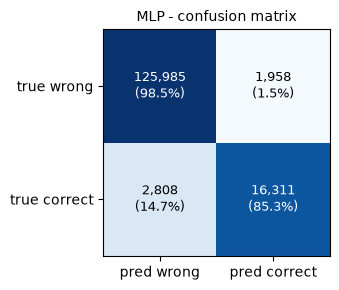

In [10]:
show_model("MLP")

**MLP training history** - training vs validation loss per epoch (64 trips train, 16 held-out trips validate):

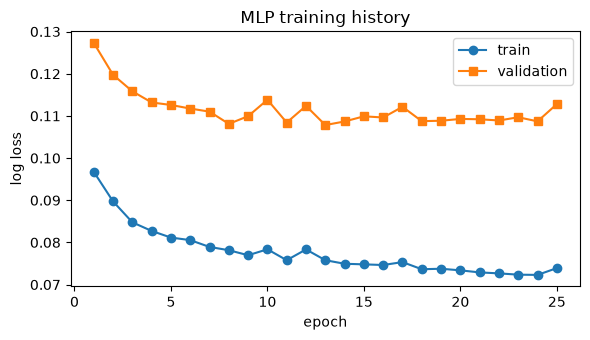

Lowest validation loss at epoch 13: after that the training loss keeps falling but validation does not (mild overfitting, early stopping limits it).


In [11]:
h = pd.read_csv(RESULTS / "models" / "mlp_epoch_history.csv")
plt.figure(figsize=(6, 3.5)); plt.plot(h.epoch, h.train_log_loss, "o-", label="train"); plt.plot(h.epoch, h.val_log_loss, "s-", label="validation")
plt.xlabel("epoch"); plt.ylabel("log loss"); plt.legend(); plt.title("MLP training history"); plt.tight_layout(); plt.show()
b = h.val_log_loss.idxmin(); print(f"Lowest validation loss at epoch {int(h.epoch[b])}: after that the training loss keeps falling but validation does not (mild overfitting, early stopping limits it).")

## Comparison of all 7 models (student-test, ranked by Top-1 accuracy)

In [12]:
comp = pd.DataFrame(live).set_index("Model").sort_values("Top-1 accuracy", ascending=False)
comp.insert(0, "CV Top-1 (mean)", summary.loc[comp.index, "cv_top1_mean"].values)
comp.insert(1, "CV Macro F1 (mean)", summary.loc[comp.index, "cv_f1_macro_mean"].values)
comp.insert(0, "Rank", range(1, len(comp) + 1))
display(comp)

,Rank,CV Top-1 (mean),CV Macro F1 (mean),Top-1 accuracy,Macro F1,Precision,Recall,Log loss,Route continuity,Predict time (s)
Model,,,,,,,,,,
LightGBM,1,0.8648,0.9269,0.8941,0.9361,0.9380,0.9343,0.0727,0.9510,1.1519
DecisionTree,2,0.8590,0.9234,0.8891,0.9338,0.9414,0.9266,0.0783,0.9495,0.0297
RandomForest,3,0.8651,0.9275,0.8828,0.9340,0.9405,0.9278,0.0717,0.9541,0.3361
MLP,4,0.8606,0.9233,0.8783,0.9270,0.9355,0.9189,0.0783,0.9510,0.2644
KNN,5,0.8459,0.9108,0.8660,0.9167,0.9257,0.9083,0.1153,0.9391,50.5339
LogisticRegression,6,0.8424,0.9041,0.8537,0.9059,0.9063,0.9054,0.1076,0.9413,0.1561
GaussianNB,7,0.6735,0.8157,0.6864,0.8138,0.7702,0.9071,1.0412,0.8910,1.9275


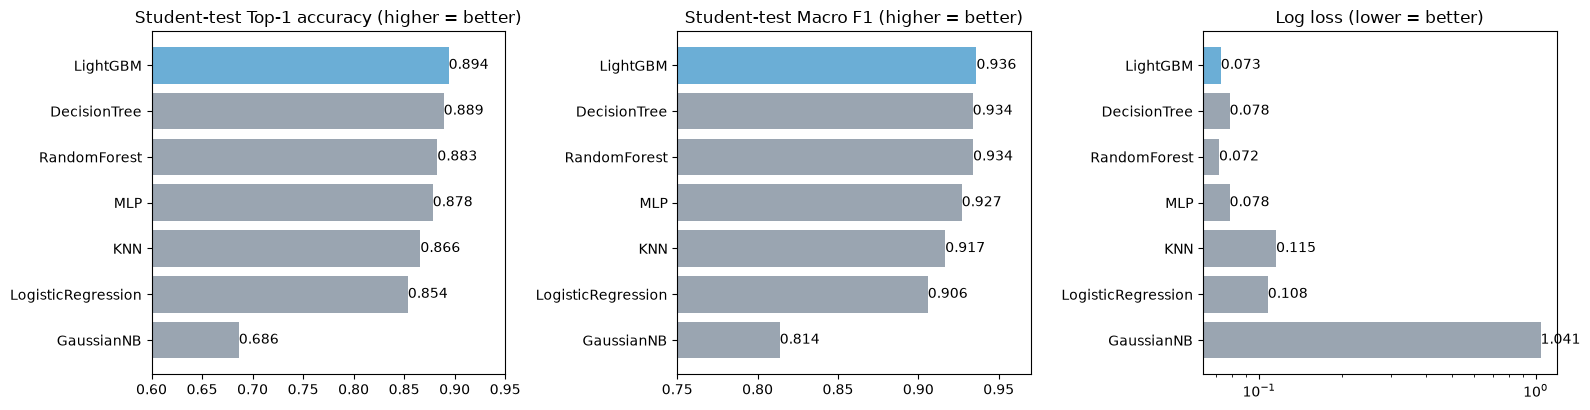

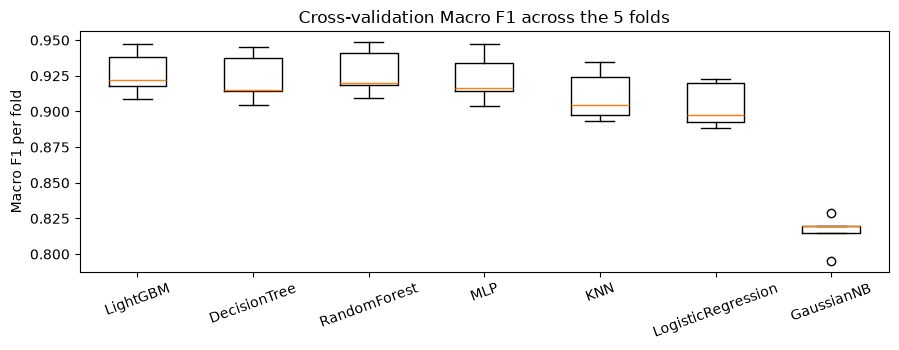

In [13]:
order = comp.index[::-1]
colors = ["#6baed6" if m == "LightGBM" else "#9aa5b1" for m in order]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
b = ax[0].barh(order, comp.loc[order, "Top-1 accuracy"], color=colors); ax[0].bar_label(b, fmt="%.3f"); ax[0].set_xlim(0.6, 0.95); ax[0].set_title("Student-test Top-1 accuracy (higher = better)")
b = ax[1].barh(order, comp.loc[order, "Macro F1"], color=colors); ax[1].bar_label(b, fmt="%.3f"); ax[1].set_xlim(0.75, 0.97); ax[1].set_title("Student-test Macro F1 (higher = better)")
b = ax[2].barh(order, comp.loc[order, "Log loss"], color=colors); ax[2].bar_label(b, fmt="%.3f"); ax[2].set_xscale("log"); ax[2].set_title("Log loss (lower = better)")
plt.tight_layout(); plt.show()

data = [cv[cv.model == m].f1_macro.values for m in comp.index]
plt.figure(figsize=(9, 3.6)); plt.boxplot(data, tick_labels=list(comp.index)); plt.ylabel("Macro F1 per fold")
plt.title("Cross-validation Macro F1 across the 5 folds"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## Selected model: LightGBM - then Bayesian tuning and HMM/Viterbi

,Top-1 accuracy
LightGBM (default),0.8941
"LightGBM (Bayes-tuned, Optuna 25 trials)",0.8991
Tuned LightGBM + HMM/Viterbi,0.9400


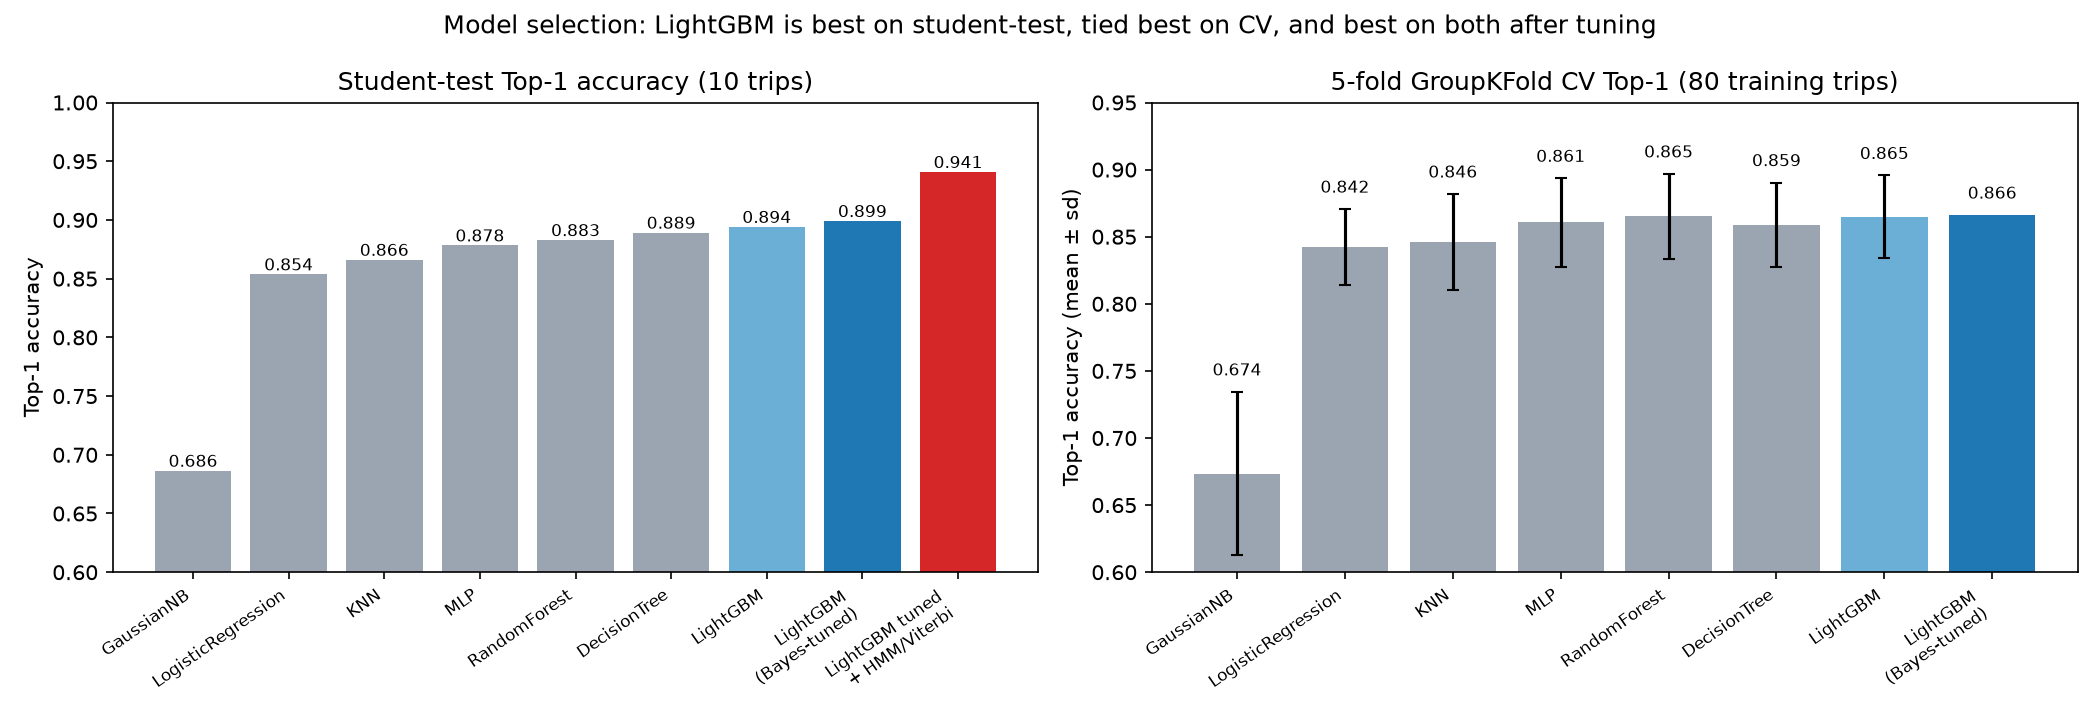

In [14]:
pred = PathSnapPredictor()                          # Bayes-tuned LightGBM + decoder settings
p = pred.model.predict_proba(X)[:, 1]
acc_t, cont_t = top1_and_continuity(p)
ok = n = 0
for tid, g in df.assign(p=p).groupby("trip_id", sort=False):
    trip, net, xy, ref = trips[tid]
    h, _ = viterbi_decode(g, g["p"].to_numpy(), net, xy, trip.track[:, 2], **pred.decoder)
    ok += int((h == ref).sum()); n += len(xy)
final = pd.DataFrame({"Top-1 accuracy": [comp.loc["LightGBM", "Top-1 accuracy"], acc_t, ok / n]},
                     index=["LightGBM (default)", "LightGBM (Bayes-tuned, Optuna 25 trials)", "Tuned LightGBM + HMM/Viterbi"])
display(final)
display(Image(filename=str(RESULTS / "plots" / "model_selection_summary.png")))

### Why LightGBM was selected
* **Best student-test Top-1 accuracy** of the 7 models (and best Macro F1).
* On cross-validation it is **tied with Random Forest** (the difference is far below the fold-to-fold spread), but it is
  faster to predict and **60x smaller** (0.16 MB vs 10 MB).
* It optimises log loss directly, so its probabilities work well as **HMM emission probabilities**.
* After **Bayesian tuning** it beats Random Forest on every metric. With **HMM/Viterbi** decoding, the final system
  reaches about **94%** Top-1 accuracy on the student-test trips.
* Naive Bayes is worst because its independence assumption is broken by our correlated distance features.